# Exercise Sheet for Interpolation and Approximation
----------------------------------------------------------

In [1]:
#load some python packages you will need
import numpy as np                 #this helps compute things
import matplotlib.pyplot as plt    #this helps plot things
from scipy import interpolate

## Question 1
### a) Compute via interpolation and plot the Lagrange polynomial p(x) to $f(x) = cos(-2\pi x) + 0.4x^2$ over
### $(x_i,y_i) = [(7.2,21.04),(7.4,21.12),(7.6,22.39),(7.8,24.77]$ 


### b) Estimate the maximum absolute error bound for this Lagrange polynomial approximation over $\xi \in [x_0,x_n]$

In [2]:
x = np.arange(7,8,0.001)   #dummy range for function
y = np.cos(-2*np.pi*x) +0.4*x**2  #function f(x)


In [3]:
xi = np.array((7.2,7.4,7.6,7.8))   # points for interpolation
yi = y[np.digitize(xi, x)]
#print(xi, yi)

"""
ok... digitize returns the index for the xi, and the x here are bins
I guess, the idea is, that I do not have an analytical function,
but just two arrays
""" 
pol = interpolate.lagrange(xi, yi)
print(pol)

#pol2 = interpolate.BarycentricInterpolator(xi, yi)

deriv_max = 16*np.pi**4/24
print ('derivative term:', deriv_max)

            3         2
-3.558e-11 x + 14.38 x - 209.6 x + 785.2
derivative term: 64.93939402266828


/var/folders/0v/hgyj042138z2mzg00d67ywzr0000gn/T/ipykernel_4479/3421765218.py:10: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  pol = interpolate.lagrange(xi, yi)


For the error bound we need for a lagrangian of degree n = 3
$$max_{[a,b]}\left|\frac{f^{(n)}(u)}{(n + 1)!}\right| max_{[a,b]}\left|\prod_{i=0}^n(x - x_i)\right|$$
and we need 
$$f' = 2 \pi \sin(-2\pi x) + 0.8 x, f'' = - 4 \pi^2 \cos(-2 \pi x) + 0.8, f^{(3)} = -8 \pi^3 \sin(-2\pi x), f^{(4)} = 16 \pi^4 \cos(-2\pi x)$$
4! = 24, the max of cosine = 1, so this first term evaluates to $\frac{32 \pi ^4}{24} = 64.94$

In [4]:
xab = np.linspace(7.2, 7.8, 1000)

product = np.ones_like(xab)
for x_ii in xi:
    product *= (xab - x_ii)

max_product = np.max(np.abs(product))
print('product term:', max_product)

tot_err = deriv_max * max_product
print('Total error bound:', tot_err)

# Now we compare directly
def fun(x):
    return np.cos(-2*np.pi*x) +0.4*x**2

error = np.max(np.abs(fun(xab) - pol(xab)))
print('Actual maximum error:', error)

product term: 0.0015999972642333354
Total error bound: 0.10390285277723986
Actual maximum error: 0.08499133162696637


And the product term shows a maximum of 0.0016, so the final estimated maximum error bound = 0.104.
The actual maximum error between the Lagrange polynom and the true function is 0.085, slightly lower than the error bound.

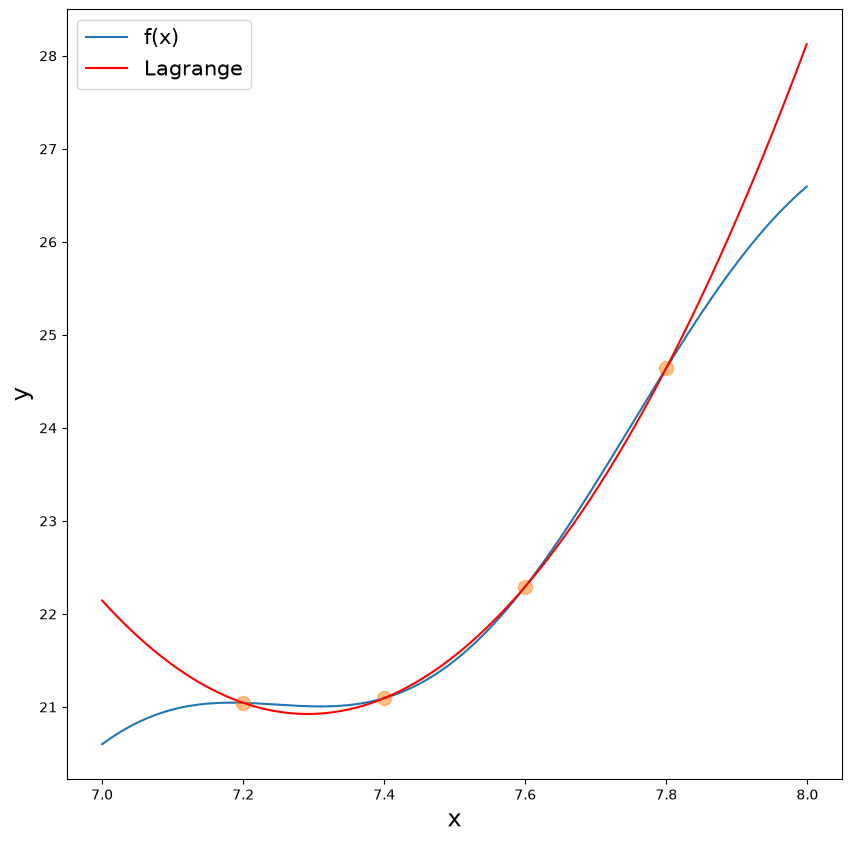

In [5]:
plt.figure(figsize=(10,10))
plt.plot(x,y,label='f(x)')  
plt.plot(xi,yi,'o',markersize=10, alpha=0.5)
plt.plot(x, pol(x), color='red', label='Lagrange')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend(loc='best',fontsize=15)




----------------------------------------------------------

## Question 2
### Assume linear interpolation with step size $\textbf{d}$ is used to approximate $y(x) = \pi x^7$
### What step size for linear interpolation do you need to have for an absolute error $E_{max} < 10^{-6}$ on the interval [0, 2]?

The general Error bound:
$$max_{[a,b]}\left|\frac{f^{(n)}(u)}{(n + 1)!}\right| max_{[a,b]}\left|\prod_{i=0}^n(x - x_i)\right|$$
takes for a linear interpolation the form:
$$max_{[a,b]}\left|\frac{f''(u)}{2!}\right| max_{[a,b]}\left|(x - x_0)(x - x_1)\right|$$
$max_{[0,2]}f'' = 7 \cdot 6 \cdot \pi \cdot 2^5$. (x - x_0)(x - x_1) is evaluated on each segment of length d, giving in the midpoint of the segment $|(-\frac{d}{2} \cdot \frac{d}{2})| = \frac{d^2}{4}$ 

So the total error is $E = \frac{7 \cdot 6 \cdot \pi \cdot 2^5 \cdot d^2}{8} = 168 \cdot \pi \cdot d^2$, solved for d: $d = \sqrt{\frac{E}{168 \cdot \pi}} = 4.35 \cdot 10^{-5}$.

Alternatively, we can start with d equal to the interval length, and iteratively halve d, until the error falls below the given criterion. Of course, this is not exact, because the optimal d might be inbetween the last and the previous halving. As can be seen below, this results in $3.05 \cdot 10^{-5}$, which is slightly below the analytical result, as expected.


In [6]:
from math import pi, sqrt

a, b = 0, 2

d = b - a
deriv = pi * 7 * 6 * b**5
for iter in range(100):
    E = deriv * d**2 / 8
    if abs(E) < 1e-6:
        break
    d /= 2

print(f'Iterated d: {d:.2e}, {iter} halvings')

print(f'Analytical result: {sqrt(1e-6 /(42 * b**5 / 8 * pi)):.2e}')



Iterated d: 3.05e-05, 16 halvings
Analytical result: 4.35e-05


----------------------------------------------------------

## Question 3
### When using Taylor polynomials to approximate $y = cos(-3 \pi x) + 3x$ over the range $x = [-0.25,0.25]$, about $x= 0$;  to what order $j$ would you need to compute the interpolating polynomial in order to keep the maximum absolute error smaller than $E_{j}(x) < 10^{-6}$?

The derivative term derived n-times is (absolute value, don't care about the (-1) factors), and alway taking the maximum of the sin/cos as 1
$$max |f'| = |3 \pi + 3|,   max |f^{n}| = (3 \pi)^n, \mathrm{for\;n > 1} $$
Below we take the formula from the lecture for Taylor series, and the maximum (x - a) = 0.25, the maximum distance of the point where we expand from the interval boundary.

In [7]:
from math import factorial, pi

for j in range(100):
    E = (0.25**(j+1))/factorial(j+1)*(3 * pi)**(j+1)
    if abs(E) <= 1e-6:
        break

print(f'Need degree {j}')


Need degree 14


/var/folders/0v/hgyj042138z2mzg00d67ywzr0000gn/T/ipykernel_4948/2976732995.py:11: DeprecationWarning: `approximate_taylor_polynomial` is deprecated and will be removed in SciPy 1.20.0.
  tayl = interpolate.approximate_taylor_polynomial(func, 0, 14, 0.5)


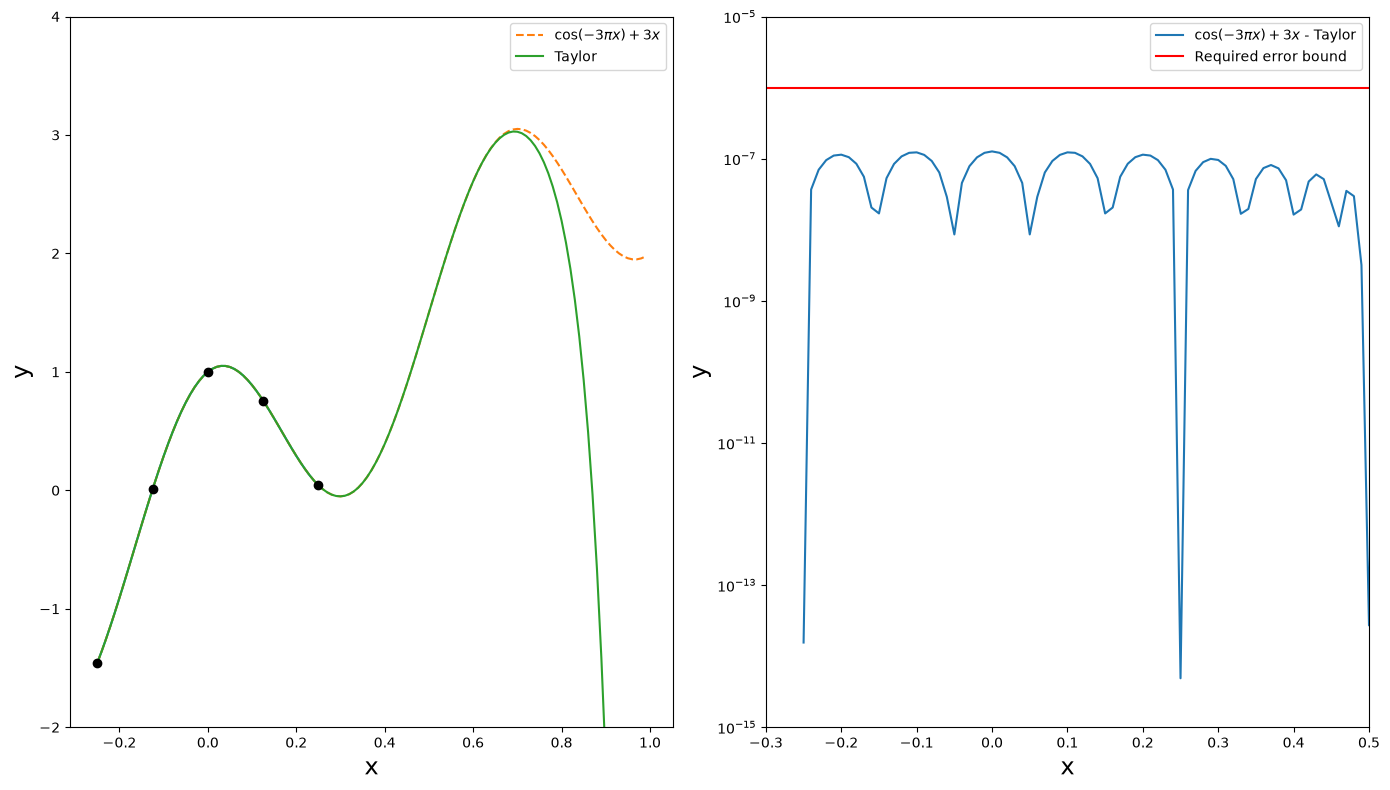

In [26]:
def func(x):
    return np.cos(-3 * np.pi * x) + 3*x

xi = np.arange(-0.25,1,0.01)
xdum = np.arange(-0.25,0.25,0.01)
x = np.array([-0.25,-0.125,0,0.125,0.25])
y = np.cos(-3*np.pi*x) + 3*x
ydum = np.cos(-3*np.pi*xdum) + 3*xdum
yi = np.cos(-3*np.pi*xi) + 3*xi

tayl = interpolate.approximate_taylor_polynomial(func, 0, 14, 0.5)
#print(tayl)

plt.figure(figsize=(14,8))

plt.subplot(1, 2, 1)
plt.plot(xdum,ydum)
plt.plot(xi,yi,'--', label=r'$\cos(-3 \pi x) + 3 x$')
plt.plot(xi, tayl(xi), label='Taylor')
plt.ylim(-2,4)
plt.plot(x,y,'o',c='black')
plt.xlabel('x',fontsize=17)
plt.ylabel('y',fontsize=17)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(xi, abs(func(xi) - tayl(xi)),
         label=r'$\cos(-3\pi x) + 3x$ - Taylor')
plt.yscale('log')
plt.xlabel('x', fontsize=17)
plt.ylabel('y', fontsize=17)
plt.axhline(1e-6, color='red', label='Required error bound')
plt.ylim(1e-15, 1e-5)
plt.xlim(-0.3, .5)
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
# replacement wrapper for the now deprecated approximate_taylor_polynomial

from numpy.polynomial import Polynomial
def taylor_fft(f, center=0, degree=14, radius=0.5, N=64):
    k = np.arange(N)

    z = center + radius * np.exp(2j * np.pi * k / N)

    c = np.fft.fft(f(z)) / N
    c = c[:degree + 1] / radius**np.arange(degree + 1)

    c = np.real(c)

    return Polynomial(c)(Polynomial([-center, 1]))

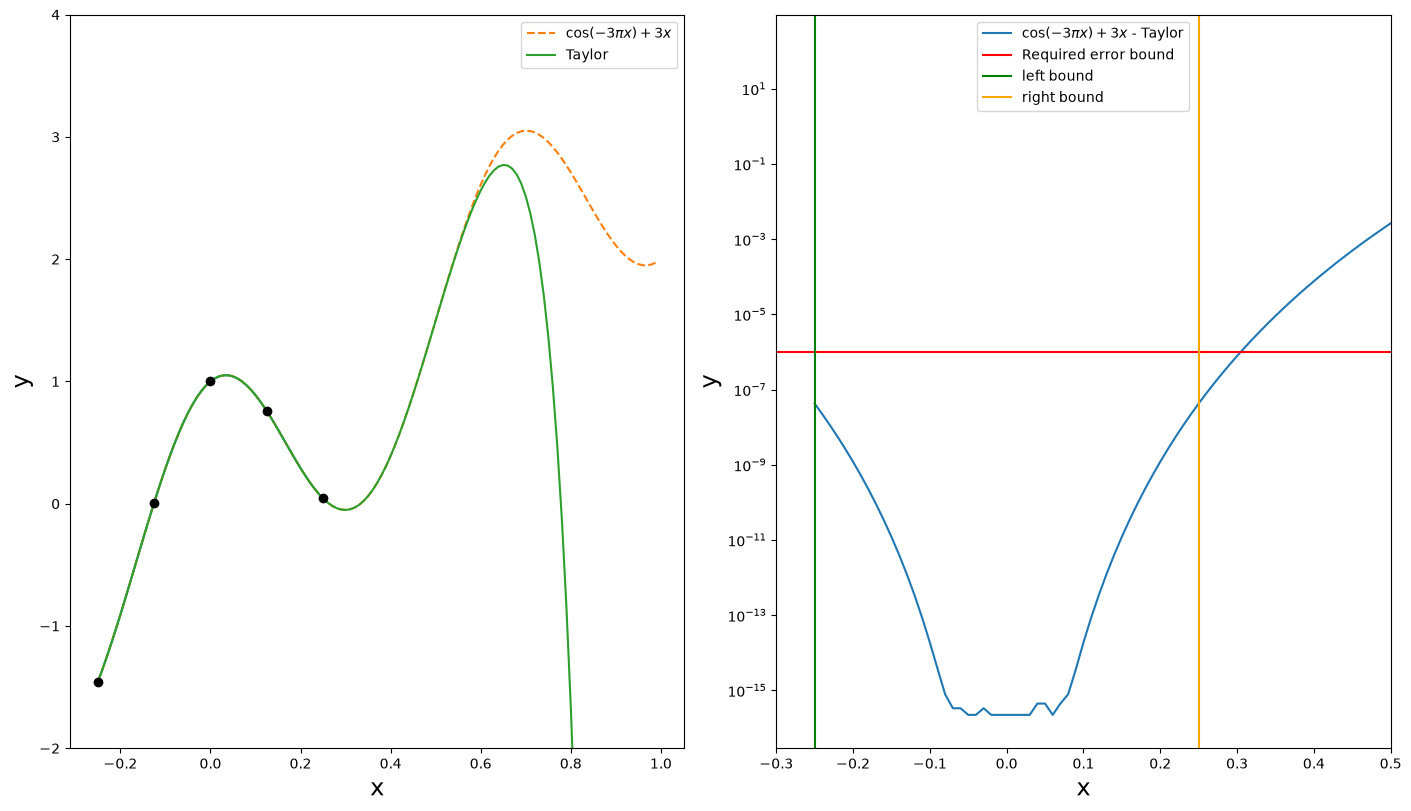

In [19]:
# Here with the replacement for Taylorfunctions

def func(x):
    return np.cos(-3 * np.pi * x) + 3*x

# Taylor polynomial parameters
degree = 14
center = 0
radius = .25
N = 32

tayl = taylor_fft(func, center, degree, radius)

xi = np.arange(-0.25, 1, 0.01)
xdum = np.arange(-0.25, 0.25, 0.01)
x = np.array([-0.25, -0.125, 0, 0.125, 0.25])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8), constrained_layout=True)

ax1.plot(xdum, func(xdum))
ax1.plot(xi, func(xi), '--',
         label=r'$\cos(-3\pi x) + 3x$')
ax1.plot(xi, tayl(xi), label='Taylor')
ax1.set_ylim(-2, 4)
ax1.plot(x, func(x), 'o', c='black')
ax1.set_xlabel('x', fontsize=17)
ax1.set_ylabel('y', fontsize=17)
ax1.legend()

#ax2.plot(xi, np.log10(abs(func(xi) - tayl(xi))),
#         label=r'$\log |(\cos(-3\pi x) + 3x$ - Taylor)|')
ax2.plot(xi, np.abs(func(xi) - tayl(xi)),
         label=r'$\cos(-3\pi x) + 3x$ - Taylor')
ax2.set_yscale('log')
ax2.set_xlabel('x', fontsize=17)
ax2.set_ylabel('y', fontsize=17)
ax2.axhline(1e-6, color='red', label='Required error bound')
ax2.axvline(-0.25, color='green', label='left bound')
ax2.axvline(+0.25, color='orange', label='right bound')
ax2.set_xlim(-0.3, 0.5)
ax2.legend()

plt.show()

----------------------------------------------------------

## Question 4
## Use bilinear interpolation to determine the value of the function $f(x,y) = z$  at the point $(x_r, y_r)$, given the below four data points $x_i, y_i$ with values $z_{i} = f(x_i,y_i)$


1.0382572582476404


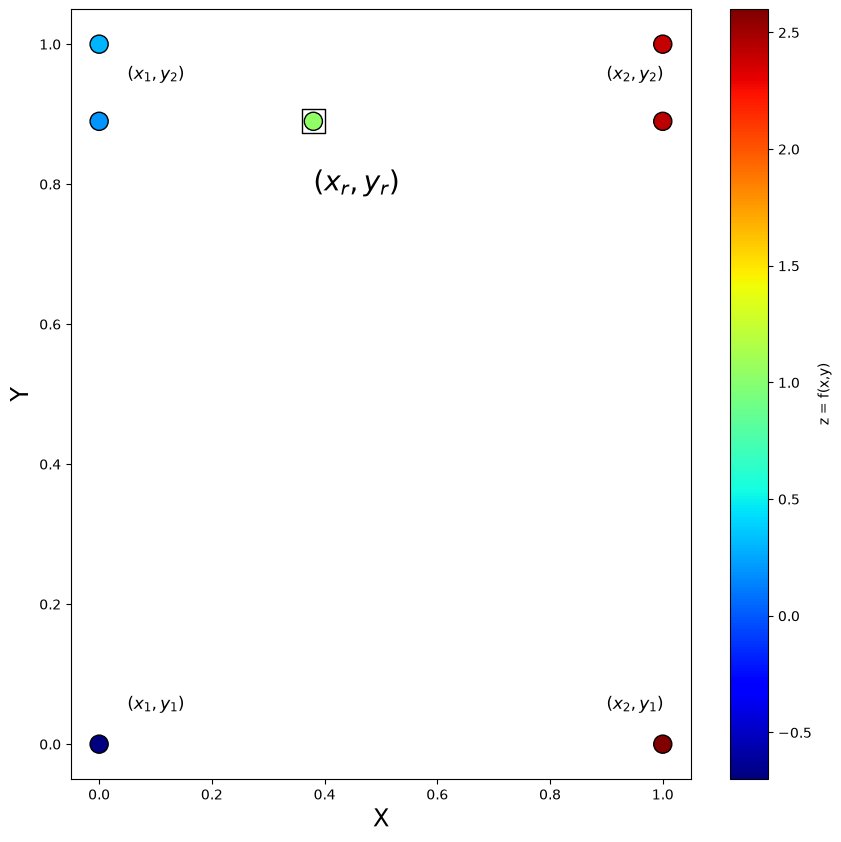

In [12]:
#Known data points and function values.  Listed clockwise from the x_1,y_1 = (0,0) point.
xi = np.array([0,0,1,1])  #x_1,x_1,x_2,x_2
yi = np.array([0,1,1,0])  #y_1,y_2,y_2,y_1
zi = np.array([-0.7,0.3,2.4,2.6])  

#Randomly generate coordinates to find function value (z = f(x,y)) at 
xr = np.random.uniform()
yr = np.random.uniform()

# first interpolate on the left y-axis
zr_left = zi[0] + (yr - yi[0]) * (zi[1] - zi[0]) / (yi[1] - yi[0])
xi = np.append(xi, [xi[0]])
yi = np.append(yi, [yr])
zi = np.append(zi, [zr_left])
# then on the right y-axis
zr_right = zi[3] + (yr - yi[3]) * (zi[2] - zi[3]) / (yi[2] - yi[3])
xi = np.append(xi, [xi[2]])
yi = np.append(yi, [yr])
zi = np.append(zi, [zr_right])
# and now along x-axis
zr = zr_left + (xr - xi[0]) * (zr_right - zr_left) / (xi[3] - xi[0])
xi = np.append(xi, [xr])
yi = np.append(yi, [yr])
zi = np.append(zi, [zr])

#Visualize
plt.figure(figsize=(10,10))
sc = plt.scatter(xi,yi,c=zi,s=170,marker='o',cmap='jet',edgecolor='black')
plt.scatter(xr,yr,edgecolor='black',marker='s',facecolor='none', s=290)
plt.colorbar(sc, label='z = f(x,y)')
plt.xlabel('X',fontsize=17)
plt.ylabel('Y',fontsize=17)

plt.text(0.05,0.05,'($x_1,y_1)$',fontsize=12)
plt.text(0.05,0.95,'($x_1,y_2)$',fontsize=12)
plt.text(0.9,0.95,'($x_2,y_2)$',fontsize=12)
plt.text(0.9,0.05,'($x_2,y_1)$',fontsize=12)
plt.text(xr,yr-0.1,'($x_r,y_r)$',fontsize=20)

print(zr)


In [13]:
# Exercise during class

a = [1, 2, 3]
b = [1, 2, 3]
c = a

print(a == b)       # I predict True
print(a is b)       # I predict False
print(a is c)       # I predict True

True
False
True


In [14]:
# from previous exercise
class Star:
    """ Klasse für Sterne"""
    def __init__(self, name, mass, radius, temperature):
        self.name = str(name)
        self.mass = float(mass)
        self.radius = float(radius)
        self.temperature = float(temperature)

    def __str__(self):
         return f'{self.name} has mass: {self.mass}, radius: {self.radius} and temperature {self.temperature}'
 
    def print_info(self):
        print(f'{self.name} has mass: {self.mass}, radius: {self.radius} and temperature {self.temperature}')
       
    def is_FGKM(self, t_limit = 7300):
        return (self.temperature < t_limit)




In [15]:
def find_star(stars, name):
    for star in stars:
        if star.name == name:
            return star
        else:
            return f'"{name}" does not exist'


sirius = Star('Sirius', 2, 3, 8000)
wega = Star('Wega', 4, 5, 6000)
rigel = Star('Rigel', 4, 5, 7000)
pollux = Star('Pollux', 5, 6, 8000)
betelgeuse = Star('Betelgeuse', 5, 6, 4000)

stars = [sirius, wega]
star = find_star(stars, "Sirius")
print(star)

star = find_star(stars, "Beteigeuze")
print(star)

giant_stars = ["Rigel", "Betelgeuse", "Pollux"]

test = [rigel, wega, pollux]
for star in test:
    if star.name in giant_stars and star.temperature > 5000:
        print(f'{star.name} is giant and hot')

Sirius has mass: 2.0, radius: 3.0 and temperature 8000.0
"Beteigeuze" does not exist
Rigel is giant and hot
Pollux is giant and hot


In [16]:
a = [1, 2, 3]
b = a
c = a.copy()

print(a == b)       # I predict True
print(a is b)       # I predict False....but my prediction was wrong!! The assignment actually creates a link
print(a == c)       # I predict True
print(a is c)       # I predict False

True
True
True
False
